# 09 · MOS robustness: Demucs, transposition, same song / different singers
**GPU runtime.** Run after `08_WavLM_MLP_v2` (needs `mos_test_preds.csv` and both exported models).
Every test is run for both models: the final one trained **without** augmentation (`pred`) and the ablation
trained **with** it (`pred_aug`).

- **Vocal separation:** the test set is scored again *after* Demucs vocal separation (the webapp separates vocals;
  training clips are already a cappella). Demucs gets audio at its native 44.1 kHz, as in `utils/predict_mos.py`.
- **Transposition:** the same clip shifted by ±1, ±2, ±3 semitones.
  **Control:** a *round trip* (+s then −s semitones) leaves the pitch unchanged but applies the same processing
  twice. If the round trip lowers the score as much as a real shift does, the drop comes from processing
  artefacts, not from the key. The rank effect is computed in `11_Ranking_Evaluation`.
- **Same song, different performers:** SingMOS-Pro segments rendered by several systems and MAST
  melodies sung by several candidates.

Embeddings of processed audio are cached on Drive, so a disconnect does not lose finished clips.

In [1]:
!pip install -q --no-deps demucs openunmix
!pip install -q dora-search julius lameenc einops

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.6/100.6 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.0/40.0 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.2/187.2 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.0/76.0 kB 7.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
demucs 4.1.0 requires sphn>=0.1.12, which is not installed.


In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import os, zipfile
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import librosa, torch
from torch import nn
from tqdm.auto import tqdm
from transformers import AutoFeatureExtractor, AutoModel
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from demucs import pretrained
from demucs.apply import apply_model

OUT = "/content/drive/MyDrive/szakdolgozat/v2"
RES = f"{OUT}/results"
AUDIO = "/content/mos_audio"
EMB_TR = f"{OUT}/emb_transpose"
SR = 16000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WAVLM_MODEL = "microsoft/wavlm-large"
SHIFTS = [-3, -2, -1, 1, 2, 3]
ROUNDTRIPS = [1, 2, 3]
N_TRANSPOSE = 400            # test clips used for the transposition experiment
SEED = 42
os.makedirs(EMB_TR, exist_ok=True)

test = pd.read_csv(f"{OUT}/mos_test_preds.csv")
need = set(test.wav)
with zipfile.ZipFile(f"{OUT}/mos_audio.zip") as z:
    z.extractall(AUDIO, members=[n for n in z.namelist() if os.path.basename(n) in need])
len(test)

1194

In [4]:
class RegressorMLP(nn.Module):
    def __init__(self, in_dim, hidden_dim=512):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(hidden_dim, hidden_dim//2),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(hidden_dim//2, 1)
        )

    def forward(self, x):
        x = self.net(x).squeeze(-1)
        return x

def load_head(path):
    head = RegressorMLP(1024).to(DEVICE)
    head.load_state_dict(torch.load(path, map_location=DEVICE))
    return head.eval()

# suffix of the prediction column in mos_test_preds.csv -> model
heads = {"": load_head(f"{OUT}/models/wavlm_mlp_mos_regressor.pt"),
         "_aug": load_head(f"{OUT}/models/wavlm_mlp_mos_regressor_aug.pt")}
HEAD_NAME = {"": "without aug (final)", "_aug": "with aug"}

extractor = AutoFeatureExtractor.from_pretrained(WAVLM_MODEL)
wavlm = AutoModel.from_pretrained(WAVLM_MODEL).to(DEVICE).eval()

# Guard: some transformers versions silently re-initialise WavLM's positional conv weights
# (checkpoint stores them as weight_g/weight_v). Two loads would then give different embeddings.
_w2 = AutoModel.from_pretrained(WAVLM_MODEL).to(DEVICE).eval()
with torch.no_grad():
    _x = torch.randn(1, SR, device=DEVICE)
    assert torch.allclose(wavlm(_x).last_hidden_state, _w2(_x).last_hidden_state, atol=1e-4), "WavLM weights not fully loaded"
del _w2
import transformers; print("transformers", transformers.__version__, "- pin this version in streamlit-webapp/requirements.txt")
demucs_model = pretrained.get_model("htdemucs").to(DEVICE).eval()

@torch.no_grad()
def embed_wave(wave):
    inputs = extractor(wave, sampling_rate=SR, return_tensors="pt").to(DEVICE)
    return wavlm(**inputs).last_hidden_state[0].mean(0).cpu().numpy()

@torch.no_grad()
def head_predict(head, E):
    return head(torch.tensor(np.asarray(E), dtype=torch.float32, device=DEVICE).reshape(-1, 1024)).cpu().numpy()

@torch.no_grad()
def demucs_vocals(wave):
    y = librosa.resample(wave, orig_sr=SR, target_sr=demucs_model.samplerate)
    x = torch.tensor(y).repeat(2, 1)[None].to(DEVICE)          # (1, 2, T) stereo
    sep = apply_model(demucs_model, x, split=True, device=DEVICE)[0]
    vocals = sep[demucs_model.sources.index("vocals")].mean(0).cpu().numpy()
    return librosa.resample(vocals, orig_sr=demucs_model.samplerate, target_sr=SR)

def load_audio(wav):
    return librosa.load(f"{AUDIO}/{wav}", sr=SR, mono=True)[0]

def metrics(t, p):
    return {"r2": r2_score(t, p), "rmse": mean_squared_error(t, p) ** 0.5, "mae": mean_absolute_error(t, p),
            "pearson": pearsonr(t, p)[0], "spearman": spearmanr(t, p)[0]}

# sanity check: re-predicting a raw clip here must match notebook 08
_e = embed_wave(load_audio(test.wav[0]))
for sfx, head in heads.items():
    assert abs(head_predict(head, _e)[0] - test["pred" + sfx][0]) < 1e-3, sfx

preprocessor_config.json:   0%|          | 0.00/214 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.22k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.26GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/488 [00:00<?, ?it/s]

...

transformers 5.20.1 - pin this version in streamlit-webapp/requirements.txt


htdemucs.yaml:   0%|          | 0.00/21.0 [00:00<?, ?B/s]

955717e8.safetensors: reconstructing file:   0%|          |  0.00B / 84.0MB            

955717e8.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:6409: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


## Raw vs Demucs-separated input

In [5]:
DEMUCS_NPZ = f"{OUT}/mos_demucs_emb.npz"
if os.path.exists(DEMUCS_NPZ):
    E_dm = np.load(DEMUCS_NPZ)["E"]
else:
    E_dm = np.stack([embed_wave(demucs_vocals(load_audio(w))) for w in tqdm(test.wav)])
    np.savez(DEMUCS_NPZ, E=E_dm)

rows = {}
for sfx, head in heads.items():
    raw, dm = test["pred" + sfx].values, head_predict(head, E_dm)
    rows[(HEAD_NAME[sfx], "raw input")] = {**metrics(test.mos, raw), "mean |Δpred|": 0.0}
    rows[(HEAD_NAME[sfx], "after Demucs")] = {**metrics(test.mos, dm), "mean |Δpred|": np.abs(dm - raw).mean()}
dm_table = pd.DataFrame(rows).T.round(3)
dm_table.to_csv(f"{RES}/mos_demucs_effect.csv"); dm_table

r2   rmse    mae  pearson  spearman  \
without aug (final) raw input     0.398  0.717  0.560    0.638     0.570   
                    after Demucs  0.396  0.718  0.563    0.638     0.568   
with aug            raw input     0.399  0.717  0.556    0.641     0.575   
                    after Demucs  0.397  0.718  0.557    0.641     0.574   

                                  mean |Δpred|  
without aug (final) raw input            0.000  
                    after Demucs         0.050  
with aug            raw input            0.000  
                    after Demucs         0.052

## Transposition with round-trip control

In [6]:
VARIANTS = [("none", 0)] + [("shift", s) for s in SHIFTS] + [("roundtrip", s) for s in ROUNDTRIPS]

def transform(y, kind, s):
    if kind == "none":
        return y
    y = librosa.effects.pitch_shift(y=y, sr=SR, n_steps=s)
    return librosa.effects.pitch_shift(y=y, sr=SR, n_steps=-s) if kind == "roundtrip" else y

sub = test.sample(min(N_TRANSPOSE, len(test)), random_state=SEED)
rows = []
for w in tqdm(sub.wav):
    y = None
    for kind, s in VARIANTS:
        path = f"{EMB_TR}/{w[:-4]}_{kind}{s:+d}.npy"
        if not os.path.exists(path):
            y = load_audio(w) if y is None else y
            np.save(path, embed_wave(transform(y, kind, s)))
        rows.append({"wav": w, "kind": kind, "shift": s, "path": path})
tr = pd.DataFrame(rows)
# reading thousands of small files from Drive one by one is slow -> parallel read once, then one consolidated file
TR_NPZ = f"{OUT}/mos_transpose_emb.npz"
cached = np.load(TR_NPZ, allow_pickle=True) if os.path.exists(TR_NPZ) else None
if cached is not None and list(cached["path"]) == tr.path.tolist():
    E_tr = cached["E"]
else:
    with ThreadPoolExecutor(32) as ex:
        E_tr = np.stack(list(tqdm(ex.map(np.load, tr.path), total=len(tr))))
    np.savez(TR_NPZ, E=E_tr, path=tr.path.values)
for sfx, head in heads.items():
    tr["pred_shift" + sfx] = head_predict(head, E_tr)
tr.drop(columns="path").to_csv(f"{OUT}/mos_transpose_preds.csv", index=False)

# delta = processed - unprocessed prediction, per model
long = []
for sfx in heads:
    base = tr[tr.kind == "none"].set_index("wav")["pred_shift" + sfx]
    t = tr[tr.kind != "none"][["wav", "kind", "shift"]].copy()
    t["model"] = HEAD_NAME[sfx]
    t["pred"] = base.loc[t.wav].values
    t["pred_shift"] = tr.loc[t.index, "pred_shift" + sfx].values
    long.append(t)
long = pd.concat(long).merge(test[["wav", "mos", "source"]], on="wav")
long["delta"] = long.pred_shift - long.pred

def shift_summary(d):
    return pd.Series({"n": len(d), "mean_delta": d.delta.mean(), "sd_delta": d.delta.std(),
                      "mean_abs_delta": d.delta.abs().mean(),
                      "share_abs_delta_gt_0.25": (d.delta.abs() > 0.25).mean(),
                      "share_abs_delta_gt_0.5": (d.delta.abs() > 0.5).mean(),
                      "spearman_vs_unshifted": spearmanr(d.pred, d.pred_shift)[0]})

ts = long.groupby(["model", "kind", "shift"])[["pred", "pred_shift", "delta"]].apply(shift_summary).round(3)
ts.to_csv(f"{RES}/mos_transposition_summary.csv"); print(ts)
(long.groupby(["model", "source", "kind", "shift"])[["pred", "pred_shift", "delta"]].apply(shift_summary)
     .round(3).to_csv(f"{RES}/mos_transposition_by_source.csv"))
for sfx in heads:
    print(f"reference: test MAE ({HEAD_NAME[sfx]}) =", round(mean_absolute_error(test.mos, test["pred" + sfx]), 3))

  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

                                         n  mean_delta  sd_delta  \
model               kind      shift                                
with aug            roundtrip  1     400.0      -1.729     0.595   
                               2     400.0      -1.782     0.602   
                               3     400.0      -1.796     0.611   
                    shift     -3     400.0      -1.573     0.603   
                              -2     400.0      -1.510     0.585   
                              -1     400.0      -1.378     0.553   
                               1     400.0      -1.513     0.550   
                               2     400.0      -1.533     0.549   
                               3     400.0      -1.560     0.553   
without aug (final) roundtrip  1     400.0      -1.451     0.615   
                               2     400.0      -1.492     0.625   
                               3     400.0      -1.502     0.637   
                    shift     -3     400.0      

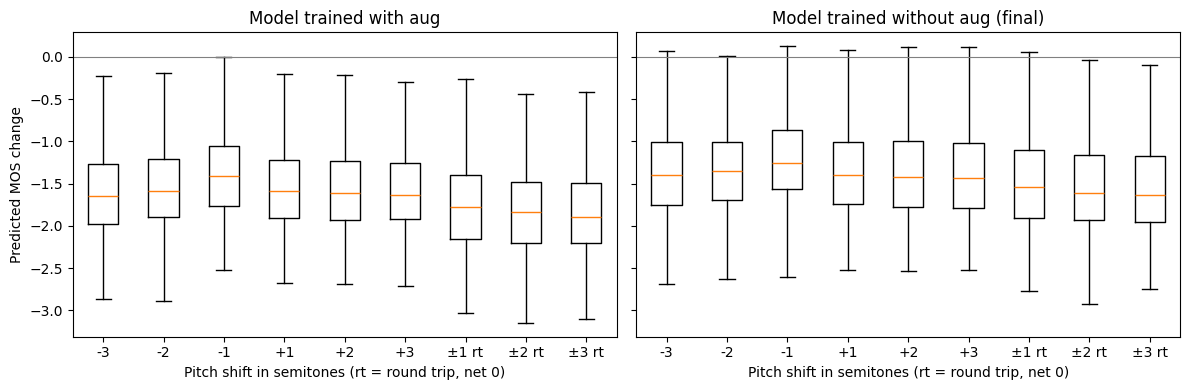

In [7]:
labels = [f"{s:+d}" for s in SHIFTS] + [f"±{s} rt" for s in ROUNDTRIPS]
keys = [("shift", s) for s in SHIFTS] + [("roundtrip", s) for s in ROUNDTRIPS]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, g) in zip(axes, long.groupby("model")):
    ax.boxplot([g.delta[(g.kind == k) & (g["shift"] == s)] for k, s in keys], showfliers=False)
    ax.set_xticks(range(1, len(keys) + 1), labels)
    ax.axhline(0, c="gray", lw=0.8)
    ax.set_title(f"Model trained {name}"); ax.set_xlabel("Pitch shift in semitones (rt = round trip, net 0)")
axes[0].set_ylabel("Predicted MOS change")
plt.tight_layout(); plt.savefig(f"{RES}/fig_mos_transposition.png", dpi=200); plt.show()

## Same song, different performers
Groups with ≥2 test clips: the same SingMOS-Pro segment from different systems, or the same MAST melody
from different candidates.
- `eta2_*` = share of variance explained by *which song* it is. If `eta2_pred` ≫ `eta2_true`, the model
  rates the song rather than the performance.
- `within_song_*` = correlation of true vs predicted MOS after removing each song's mean, i.e. how well the
  model ranks different performers of the same song.

In [8]:
def eta2(v, groups):
    v = pd.Series(np.asarray(v, dtype=float))
    gm = v.groupby(np.asarray(groups)).transform("mean")
    return ((gm - v.mean()) ** 2).sum() / ((v - v.mean()) ** 2).sum()

multi = test[test.groupby("group").wav.transform("size") >= 2]
rows = []
for sfx in heads:
    col = "pred" + sfx
    for src, g in multi.groupby("source"):
        wt = g.mos - g.groupby("group").mos.transform("mean")
        wp = g[col] - g.groupby("group")[col].transform("mean")
        rows.append({"model": HEAD_NAME[sfx], "source": src, "clips": len(g), "songs": g.group.nunique(),
                     "eta2_true": eta2(g.mos, g.group), "eta2_pred": eta2(g[col], g.group),
                     "within_song_pearson": pearsonr(wt, wp)[0], "within_song_spearman": spearmanr(wt, wp)[0]})
same_song = pd.DataFrame(rows).round(3)
same_song.to_csv(f"{RES}/mos_same_song.csv", index=False); same_song

,model,source,clips,songs,eta2_true,eta2_pred,within_song_pearson,within_song_spearman
0,without aug (final),mast,95,4,0.128,0.028,0.440,0.466
1,without aug (final),singmos,988,136,0.227,0.467,0.614,0.590
2,with aug,mast,95,4,0.128,0.034,0.439,0.471
3,with aug,singmos,988,136,0.227,0.476,0.620,0.591
